# Pandas CSV Lab With Sample Data

This lab demonstrates how to work with CSV files using the pandas library. In this notebook, you will:

- Import libraries
- Create and load sample CSV data
- Explore and clean the dataset
- Filter, group, and aggregate data
- Merge datasets, create pivot tables, and handle time series data
- Export data back to CSV

Each section includes exercises with detailed instructions. Enjoy and feel free to modify the code for additional exploration!

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# For reproducibility
np.random.seed(0)

## 1. Creating Sample Data

Since you might not have CSV files on hand, we will first create sample data and write them to CSV files. Two files will be generated:

- `your_data.csv`: Contains sample employee data.
- `departments.csv`: Contains sample department information.

In [ ]:
# Create a sample DataFrame for main data
sample_data = {
    'Name': ['Alice', 'Bob', 'Charlie', 'David', 'Eva'],
    'Age': [25, 35, 45, 29, 55],
    'Salary': [50000, 75000, 110000, 50000, 90000],
    'Department': ['HR', 'Finance', 'HR', 'Engineering', 'Finance'],
    'Gender': ['F', 'M', 'M', 'M', 'F'],
    'Hire_Date': ['2021-01-15', '2020-07-23', '2020-07-23', '2021-12-11', '2018-03-14']
}

df_sample = pd.DataFrame(sample_data)

# Write the sample DataFrame to CSV
sample_filename = 'your_data.csv'
df_sample.to_csv(sample_filename, index=False)

print('Sample main data written to', sample_filename)
df_sample.head()

Sample main data written to your_data.csv


,Name,Age,Salary,Department,Gender,Hire_Date
0,Alice,25,50000,HR,F,2021-01-15
1,Bob,35,75000,Finance,M,2020-07-23
2,Charlie,45,110000,HR,M,2019-05-01
3,David,29,50000,Engineering,M,2021-12-11
4,Eva,55,90000,Finance,F,2018-03-14


## 2. Creating Department Data

Now, create a second CSV file that contains department details. This file will later be merged with the main dataset.

In [20]:
# Create a sample DataFrame for department data
sample_dept = {
    'Department': ['HR', 'Finance', 'Engineering'],
    'Department_ID': [1, 2, 3],
    'Department_Manager': ['Laura', 'James', 'Linda']
}

df_dept = pd.DataFrame(sample_dept)

# Write the department DataFrame to CSV
dept_filename = 'departments.csv'
df_dept.to_csv(dept_filename, index=False)

print('Department data written to', dept_filename)
df_dept.head()

Department data written to departments.csv


,Department,Department_ID,Department_Manager
0,HR,1,Laura
1,Finance,2,James
2,Engineering,3,Linda


In [21]:
reload = pd.read_csv(dept_filename)
reload.head()

,Department,Department_ID,Department_Manager
0,HR,1,Laura
1,Finance,2,James
2,Engineering,3,Linda


## 3. Loading the CSV File

Load the main dataset from the CSV file we just created. (If you already have a CSV file, change the file path accordingly.)

In [22]:
# Load the main dataset
df = pd.read_csv('your_data.csv')
df.head()

,Name,Age,Salary,Department,Gender,Hire_Date
0,Alice,25,50000,HR,F,2021-01-15
1,Bob,35,75000,Finance,M,2020-07-23
2,Charlie,45,110000,HR,M,2019-05-01
3,David,29,50000,Engineering,M,2021-12-11
4,Eva,55,90000,Finance,F,2018-03-14


## 4. Exploring the Dataset

Inspect the dataset using some of the built-in pandas methods. This helps you understand the structure and summary statistics of the data.

In [23]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Name        5 non-null      object
 1   Age         5 non-null      int64 
 2   Salary      5 non-null      int64 
 3   Department  5 non-null      object
 4   Gender      5 non-null      object
 5   Hire_Date   5 non-null      object
dtypes: int64(2), object(4)
memory usage: 368.0+ bytes


,Age,Salary
count,5.000000,5.000000
mean,37.800000,75000.000000
std,12.214745,25980.762114
min,25.000000,50000.000000
25%,29.000000,50000.000000
50%,35.000000,75000.000000
75%,45.000000,90000.000000
max,55.000000,110000.000000


## 5. Data Cleaning

Check for missing values and handle them appropriately. Here, we demonstrate how to fill numerical missing values with the column mean (if any exist).

In [24]:
# Check for missing values
print(df.isnull().sum())

# If needed, fill missing values in numeric columns with the column mean
for col in df.select_dtypes(include='number').columns:
    df[col].fillna(df[col].mean(), inplace=True)

df.head()

Name          0
Age           0
Salary        0
Department    0
Gender        0
Hire_Date     0
dtype: int64


C:\Users\C0D3\AppData\Local\Temp\ipykernel_52048\3047095354.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].mean(), inplace=True)


,Name,Age,Salary,Department,Gender,Hire_Date
0,Alice,25,50000,HR,F,2021-01-15
1,Bob,35,75000,Finance,M,2020-07-23
2,Charlie,45,110000,HR,M,2019-05-01
3,David,29,50000,Engineering,M,2021-12-11
4,Eva,55,90000,Finance,F,2018-03-14


In [25]:
print(df.isnull().sum())

Name          0
Age           0
Salary        0
Department    0
Gender        0
Hire_Date     0
dtype: int64


## 6. Data Filtering and Selection

Filter rows based on specific conditions. For example, below we filter to select only those rows where `Age` is greater than 30.

In [26]:
# Filter rows where Age > 30
filtered_df = df[df['Age'] > 30]
filtered_df
abc = df[(df["Age"] > 30) | (df["Salary"] > 60000)]
abc.head()

,Name,Age,Salary,Department,Gender,Hire_Date
1,Bob,35,75000,Finance,M,2020-07-23
2,Charlie,45,110000,HR,M,2019-05-01
4,Eva,55,90000,Finance,F,2018-03-14


## 7. Grouping and Aggregation

Group the data by a categorical variable (here, `Department`) and compute aggregate statistics such as the mean salary.

In [27]:
# Group by 'Department' and calculate mean salary
grouped = df.groupby('Department')["Salary"].mean()
grouped

Department
Engineering    50000.0
Finance        82500.0
HR             80000.0
Name: Salary, dtype: float64

## 8. Simple Visualization

Visualize the distribution of the `Salary` column using a histogram.

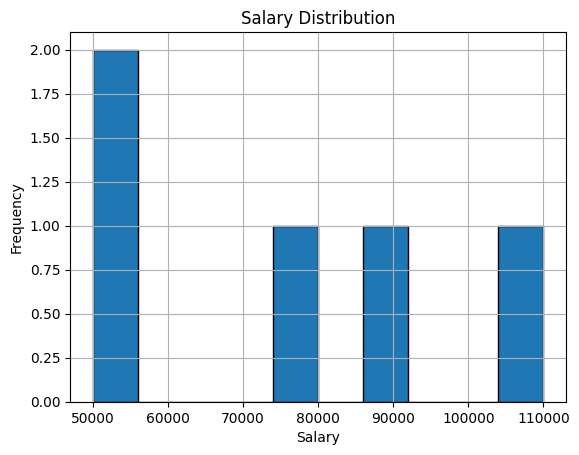

In [31]:
df['Salary'].hist(bins=10, edgecolor='black')
plt.xlabel('Salary')
plt.ylabel('Frequency')
plt.title('Salary Distribution')
plt.show()

## 9. Detailed Exercises

The following exercises dive deeper into pandas operations. Try solving these on your own, then run the corresponding code cells to review the solutions and expand your understanding.

### Exercise 9.1: Advanced Data Filtering and Transformation

1. **Filter Data:** Create a new DataFrame that contains only the rows where `Age` is greater than 30 and `Salary` is greater than 50,000.
2. **Create a New Column:** In this filtered DataFrame, add a column named `Salary_Age_Ratio` representing the ratio of `Salary` to `Age`.
3. **Group Data:** Group by `Department` and calculate the average `Salary_Age_Ratio` for each group.

In [32]:
# Exercise 9.1: Advanced Filtering and Transformation
filtered_advanced = df[(df['Age'] > 30) & (df['Salary'] > 50000)].copy()
filtered_advanced['Salary_Age_Ratio'] = filtered_advanced['Salary'] / filtered_advanced['Age']

ratio_grouped = filtered_advanced.groupby('Department')['Salary_Age_Ratio'].mean()
print(ratio_grouped)

Department
Finance    1889.610390
HR         2444.444444
Name: Salary_Age_Ratio, dtype: float64


### Exercise 9.2: Merging Datasets

1. **Load the Department Data:** Read the `departments.csv` file into a DataFrame.
2. **Merge Data:** Merge it with the main DataFrame (on the `Department` column).
3. **Examine the Result:** Display the first few rows of the merged DataFrame.

In [33]:
# Exercise 9.2: Merging Datasets
departments_df = pd.read_csv('departments.csv')
merged_df = pd.merge(df, departments_df, on='Department')
merged_df.head()

,Name,Age,Salary,Department,Gender,Hire_Date,Department_ID,Department_Manager
0,Alice,25,50000,HR,F,2021-01-15,1,Laura
1,Bob,35,75000,Finance,M,2020-07-23,2,James
2,Charlie,45,110000,HR,M,2019-05-01,1,Laura
3,David,29,50000,Engineering,M,2021-12-11,3,Linda
4,Eva,55,90000,Finance,F,2018-03-14,2,James


### Exercise 9.3: Creating Pivot Tables

1. Create a pivot table that displays the average `Salary` for each `Department` segmented by `Gender`.

In [34]:
# Exercise 9.3: Creating a Pivot Table
pivot_table = pd.pivot_table(
    df,
    values='Salary',
    index='Department',
    columns='Gender',
    aggfunc='mean'
)
print(pivot_table)

Gender             F         M
Department                    
Engineering      NaN   50000.0
Finance      90000.0   75000.0
HR           50000.0  110000.0


### Exercise 9.4: Handling Dates and Time Series

1. Convert the `Hire_Date` column to datetime format.
2. Create a new column `Hire_Month` extracting the month from `Hire_Date`.
3. Group by `Hire_Month` and plot the number of hires per month.

Hire_Month
2018-03    1
2019-05    1
2020-07    1
2021-01    1
2021-12    1
Freq: M, dtype: int64


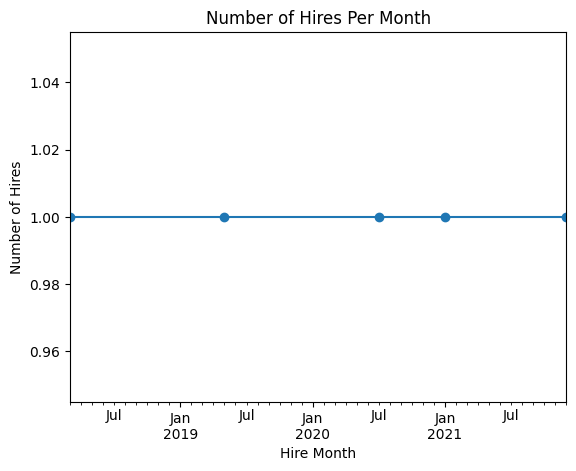

In [35]:
# Exercise 9.4: Handling Dates and Time Series
df['Hire_Date'] = pd.to_datetime(df['Hire_Date'])
df['Hire_Month'] = df['Hire_Date'].dt.to_period('M')

hires_by_month = df.groupby('Hire_Month').size()
print(hires_by_month)

hires_by_month.plot(kind='line', marker='o')
plt.xlabel('Hire Month')
plt.ylabel('Number of Hires')
plt.title('Number of Hires Per Month')
plt.show()

### Exercise 9.5: Exporting Data

1. Export the final state of the main DataFrame (or any modified DataFrame) to a CSV file named `cleaned_data.csv`.

In [ ]:
# Exercise 9.5: Exporting Data
df.to_csv('cleaned_data.csv', index=False)
print('Data exported to cleaned_data.csv')

## 10. Conclusion

In this lab you have learned how to:

- Create sample CSV files and load them into pandas
- Explore your dataset using basic methods
- Clean the data by handling missing values
- Filter, group, and aggregate data
- Merge datasets and create pivot tables
- Handle dates and plot time series data
- Export data to CSV

Feel free to modify and extend these examples as you continue your journey with data analysis using pandas.